# Chapter 3 · Solving systems

*Book 1 · Linear Algebra · Shelf I*

**Builds on:** [Chapter 2](02-matrices-as-maps.ipynb) -- a matrix as a map, its inverse.
**You will:** solve $Ax = b$ by Gaussian elimination written by hand, factor $A = LU$ and reuse
the factors, and meet the condition number -- the reason a correct algorithm can still return a
wrong answer.

Solving $Ax = b$ asks: which input $x$ does the map $A$ send to $b$? It is the most common
computation in all of numerical work -- every regression, every simulation step, every Newton
iteration runs one.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as sla

from ds_toolbox import viz

viz.use_style()

## Gaussian elimination, by hand

Subtract multiples of each row from the rows below it until the matrix is upper triangular, then
solve from the bottom up. Swapping in the row with the largest pivot (**partial pivoting**)
keeps the multipliers small.

In [2]:
def solve(A, b):
    A, b = A.astype(float).copy(), b.astype(float).copy()
    n = len(b)
    for k in range(n):
        p = k + np.argmax(np.abs(A[k:, k]))            # partial pivoting
        A[[k, p]], b[[k, p]] = A[[p, k]], b[[p, k]]
        for i in range(k + 1, n):
            m = A[i, k] / A[k, k]
            A[i, k:] -= m * A[k, k:]
            b[i] -= m * b[k]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):                     # back substitution
        x[i] = (b[i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
    return x

rng = np.random.default_rng(3)
A = rng.normal(size=(5, 5))
b = rng.normal(size=5)
print("by hand:", solve(A, b).round(6))
print("numpy:  ", np.linalg.solve(A, b).round(6))

by hand: [ 4.260531  2.229334 -4.390454 -0.352415  1.81573 ]
numpy:   [ 4.260531  2.229334 -4.390454 -0.352415  1.81573 ]


## LU: do the elimination once

The elimination steps depend only on $A$. Recording them gives $PA = LU$: a lower-triangular $L$
holding the multipliers and the upper-triangular $U$ the elimination produced. With the factors
kept, each new right-hand side costs two cheap triangular solves instead of a new elimination.

In [3]:
P, L, U = sla.lu(A)
print("P L U == A ?", np.allclose(P @ L @ U, A))
n = 1500
big = rng.normal(size=(n, n))
rhs = rng.normal(size=(n, 50))
t0 = time.perf_counter()
for j in range(50):
    np.linalg.solve(big, rhs[:, j])
fresh = time.perf_counter() - t0
t0 = time.perf_counter()
lu_piv = sla.lu_factor(big)
for j in range(50):
    sla.lu_solve(lu_piv, rhs[:, j])
reused = time.perf_counter() - t0
print(f"50 right-hand sides, n = {n}: solve each time {fresh:.2f} s · factor once {reused:.2f} s "
      f"({fresh / reused:.0f}x faster)")

P L U == A ? True


50 right-hand sides, n = 1500: solve each time 2.75 s · factor once 0.07 s (40x faster)


## Never invert to solve

$x = A^{-1}b$ is the textbook formula and the wrong computation: forming the inverse costs more
than one solve and loses accuracy. `np.linalg.solve` (an LU underneath) is the right call.

## The condition number

Some systems are fragile: a tiny change in $b$ moves $x$ a lot. The **condition number**
$\kappa(A)$ bounds how much relative error in the data can grow in the answer; with
double-precision numbers (about 16 digits) you lose roughly $\log_{10}\kappa$ of them. The
Hilbert matrix, $H_{ij} = 1/(i + j + 1)$, is the classic example.

Hilbert  4: condition   1.6e+04 · largest error in x  6.6e-14
Hilbert  8: condition   1.5e+10 · largest error in x  1.2e-07
Hilbert 10: condition   1.6e+13 · largest error in x  1.7e-04
Hilbert 12: condition   1.8e+16 · largest error in x  7.0e-01
Hilbert 14: condition   9.3e+17 · largest error in x  8.9e+00


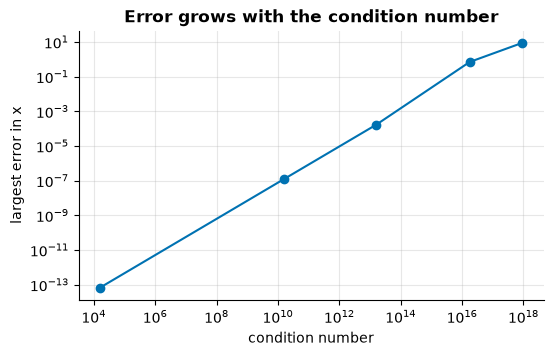

In [4]:
rows = []
for size in (4, 8, 10, 12, 14):
    H = sla.hilbert(size)
    x_true = np.ones(size)
    x_hat = np.linalg.solve(H, H @ x_true)
    rows.append((size, np.linalg.cond(H), np.abs(x_hat - x_true).max()))
for size, kappa, err in rows:
    print(f"Hilbert {size:2d}: condition {kappa:9.1e} · largest error in x {err:8.1e}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog([r[1] for r in rows], [r[2] for r in rows], marker="o")
ax.set(xlabel="condition number", ylabel="largest error in x", title="Error grows with the condition number");

The algorithm is the same in every row and does nothing wrong. The *problem* gets worse: by size
12 the answer has lost most of its digits. Checking the condition number before trusting a
solution is part of solving.

## What to remember

- Gaussian elimination with pivoting solves $Ax = b$; LU records it for reuse.
- Solve, never invert.
- The condition number says how much of the answer you can trust.

## Exercises

1. Remove the pivoting from `solve` and try `A = [[1e-18, 1], [1, 1]]`. What happens?
2. Count the floating-point operations of elimination for an $n \times n$ matrix. Check the
   $n^3$ growth by timing $n = 500, 1000, 2000$.
3. Perturb $b$ by $10^{-10}$ in the Hilbert 12 system. How far does $x$ move?

**Next:** [Chapter 4 · Orthogonality and least squares](04-orthogonality-and-least-squares.ipynb)